# Работа с SQL базой в Python

База данных sakila - учебна база от разработчиков mysql. Она описывает работу вымышленного магазина проката DVD-дисков. Структура базы описана в файле `sakila-en.a4.pdf`.

Подключение к базе выполняется следующим образом.

In [13]:
import mysql.connector

user='admin'
password='admin'
host='localhost'
port=3306
database='sakila'

try:
    cnx = mysql.connector.connect(
        user=user, password=password,
        host=host, port=port, database=database)
    print(f"""Подключение установлено:
хост: {cnx.server_host}
порт: {cnx.server_port}
пользователь: {cnx.user}""")
except mysql.connector.Error as e:
    print(f"Ошибка подключения к серверу:\n{e}")

cursor = cnx.cursor()  
  

Подключение установлено:
хост: localhost
порт: 3306
пользователь: admin


## Задание 1
Используя таблицы `rental` и `customer`, напишите запрос, который будет подсчитывать, сколько заказов сделал каждый из клиентов.

Пример выполнения задания:

In [11]:
qu = """
select c.first_name, c.last_name, count(*) as cnt from rental r
join customer c  on r.customer_id = c.customer_id
group by c.customer_id
order by cnt desc
limit 10
"""

После выполнения этого запроса объект `cursor` предоставляет генератор, по которому можно итерировать в цикле `for`. Так как этоо генератор, то итерировать можно только один раз. Чтобы выполнить итерации повторно, нужно снова выполнить запрос.

In [12]:
cursor.execute(qu)
for rec in cursor:
    print(f"{rec}")

NameError: name 'cursor' is not defined

При помощи метода `.fetchall` можно получить результаты запроса в виде списка. 

In [ ]:
cursor.execute(qu)
data = cursor.fetchall()
print(data)

[('ELEANOR', 'HUNT', 46), ('KARL', 'SEAL', 45), ('CLARA', 'SHAW', 42), ('MARCIA', 'DEAN', 42), ('TAMMY', 'SANDERS', 41), ('SUE', 'PETERS', 40), ('WESLEY', 'BULL', 40), ('MARION', 'SNYDER', 39), ('RHONDA', 'KENNEDY', 39), ('TIM', 'CARY', 39)]


Выполнить запрос, привести имена и фамилии к нижнему регистру кроме перовой буквы, собрать их вместе и построить столбцовую диаграмму заказов первых 10 самых "преданных" клиентов.

In [ ]:
cursor.execute(qu)
names = []
cnts = []
for first_name, last_name, cnt in cursor:
    names.append(f"{first_name[0] + first_name[1:].lower()} {last_name[0] + last_name[1:].lower()}")
    cnts.append(cnt)

print(names)
print(cnts)

['Eleanor Hunt', 'Karl Seal', 'Clara Shaw', 'Marcia Dean', 'Tammy Sanders', 'Sue Peters', 'Wesley Bull', 'Marion Snyder', 'Rhonda Kennedy', 'Tim Cary']
[46, 45, 42, 42, 41, 40, 40, 39, 39, 39]


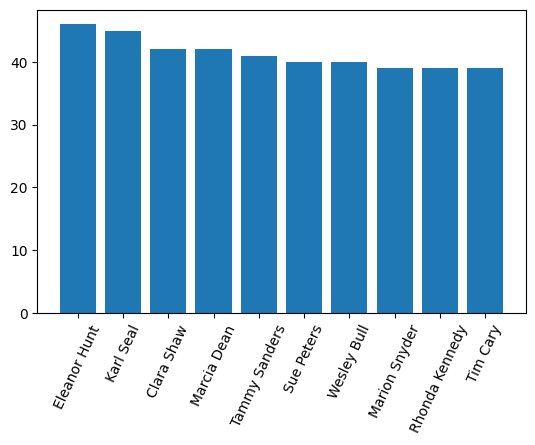

In [ ]:
import matplotlib.pyplot as plt
cm = 1.0 / 2.54

fig, ax = plt.subplots(figsize=(16*cm, 10*cm))
ax.bar(names, cnts)
ax.tick_params(axis='x', labelrotation=65)

## Задание 2

Постройте запрос, возвращающий количество фильмов, в которых снимался каждый актёр из числа тех, что внесены в базу. Для десяти наиболее популярных актёров постройте столбчатую диаграмму с горизонтальными столбцам: по оси абсцисс отложите имена и фамилии актёров, по оси ординат - число фильмов.

In [ ]:
# Ваш код:
qu = """
SELECT a.first_name, a.last_name, COUNT(fa.film_id) AS films_count
FROM actor a
JOIN film_actor fa ON a.actor_id = fa.actor_id
GROUP BY a.actor_id
ORDER BY films_count DESC
LIMIT 10;
"""

In [ ]:
cursor.execute(qu)
names = []
cnts = []
for first_name, last_name, films_count in cursor:
    names.append(f"{first_name[0] + first_name[1:].lower()} {last_name[0] + last_name[1:].lower()}")
    cnts.append(films_count)

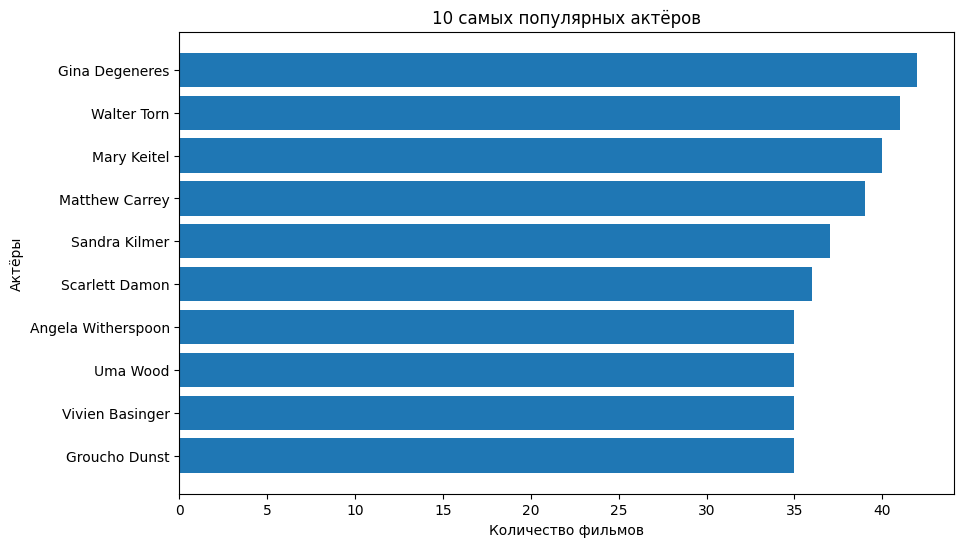

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(names, cnts) 
ax.set_xlabel("Количество фильмов")
ax.set_ylabel("Актёры")
ax.set_title("10 самых популярных актёров")
plt.gca().invert_yaxis()
plt.show()

## Задание 3

Постройте запрос, который подсчитывает количество копий (дисков) каждого из фильмов. Используя Python, получите список фильмов для которых имеется больше всего копий.

In [ ]:
# Ваш код:
qu = """
SELECT f.title, COUNT(i.inventory_id) AS copies
FROM film f
JOIN inventory i ON f.film_id = i.film_id
GROUP BY f.film_id
ORDER BY copies DESC;
"""

In [ ]:
cursor.execute(qu)
films = cursor.fetchall()
max_copies = films[0][1]
top_films = [title for title, copies in films if copies == max_copies]

In [ ]:
print("Фильмы с наибольшим количеством копий:")
for film in top_films:
    print(film)

Фильмы с наибольшим количеством копий:
ACADEMY DINOSAUR
APACHE DIVINE
BEVERLY OUTLAW
BINGO TALENTED
BOOGIE AMELIE
BOUND CHEAPER
BUCKET BROTHERHOOD
BUTTERFLY CHOCOLAT
CAT CONEHEADS
CONFIDENTIAL INTERVIEW
CROSSROADS CASUALTIES
CUPBOARD SINNERS
CURTAIN VIDEOTAPE
DANCING FEVER
DEER VIRGINIAN
DINOSAUR SECRETARY
DOGMA FAMILY
DYNAMITE TARZAN
EXPENDABLE STALLION
FAMILY SWEET
FORWARD TEMPLE
FROST HEAD
GARDEN ISLAND
GIANT TROOPERS
GILMORE BOILED
GLEAMING JAWBREAKER
GOODFELLAS SALUTE
GREATEST NORTH
GRIT CLOCKWORK
HARRY IDAHO
HEAVYWEIGHTS BEAST
HOBBIT ALIEN
HORROR REIGN
HUSTLER PARTY
INNOCENT USUAL
INVASION CYCLONE
JUGGLER HARDLY
KISS GLORY
LOATHING LEGALLY
LOSE INCH
MARRIED GO
METROPOLIS COMA
MOCKINGBIRD HOLLYWOOD
MOON BUNCH
MUSCLE BRIGHT
NETWORK PEAK
OPERATION OPERATION
PITY BOUND
PRIMARY GLASS
PULP BEVERLY
RIDGEMONT SUBMARINE
ROCKETEER MOTHER
ROSES TREASURE
RUGRATS SHAKESPEARE
RUSH GOODFELLAS
SATURDAY LAMBS
SCALAWAG DUCK
SEABISCUIT PUNK
SHOCK CABIN
SPY MILE
STING PERSONAL
STORM HAPPINESS
STREET

## Задание 4

Постройте запрос, который строит список названий фильмов, начинающихся на 'Z', и адресов по которым хранятся соответствующие диски.

In [ ]:
# Ваш код:
qu = """
SELECT f.title, a.address
FROM film f
JOIN inventory i ON f.film_id = i.film_id
JOIN store s ON i.store_id = s.store_id
JOIN address a ON s.address_id = a.address_id
WHERE f.title LIKE 'Z%';
"""

In [ ]:
cursor.execute(qu)
for title, address in cursor:
    print(f"{title} —> {address}")

ZHIVAGO CORE —> 28 MySQL Boulevard
ZHIVAGO CORE —> 28 MySQL Boulevard
ZOOLANDER FICTION —> 28 MySQL Boulevard
ZOOLANDER FICTION —> 28 MySQL Boulevard
ZOOLANDER FICTION —> 28 MySQL Boulevard
ZOOLANDER FICTION —> 47 MySakila Drive
ZOOLANDER FICTION —> 47 MySakila Drive
ZORRO ARK —> 28 MySQL Boulevard
ZORRO ARK —> 28 MySQL Boulevard
ZORRO ARK —> 28 MySQL Boulevard
ZORRO ARK —> 28 MySQL Boulevard
ZORRO ARK —> 47 MySakila Drive
ZORRO ARK —> 47 MySakila Drive
ZORRO ARK —> 47 MySakila Drive
ZORRO ARK —> 47 MySakila Drive


## Задание 5

Постройте и выполните запрос, который выводит адреса хранилищ дисков и количество дисков в каждом из них.

In [ ]:
# Ваш код:
qu = """
SELECT a.address, COUNT(i.inventory_id) AS disks_count
FROM store s
JOIN address a ON s.address_id = a.address_id
JOIN inventory i ON s.store_id = i.store_id
GROUP BY a.address;
"""

In [ ]:
cursor.execute(qu)
for address, disks_count in cursor:
    print(f"{address} = {disks_count} дисков")

47 MySakila Drive = 2270 дисков
28 MySQL Boulevard = 2311 дисков


## Задание 6

Постройте и выполните запрос, который подсчитывает количество взятых в прокат дисков по месяцам. Постройте на основе его результаиа столбчатую диаграмму, в которой по оси абсцисс были бы отложены месяцы, от января до декабря включительно, а по оси ординат — количество взятых дисков. Вероятно, потребуется использовать модуль calendar.

In [ ]:
import calendar

In [ ]:
# Ваш код:
qu = """
SELECT MONTH(r.rental_date) AS month, COUNT(*) AS rentals
FROM rental r
GROUP BY month
ORDER BY month;
"""

In [ ]:
cursor.execute(qu)
months = []
rentals = []
for month, count in cursor:
    months.append(calendar.month_name[month]) 
    rentals.append(count)

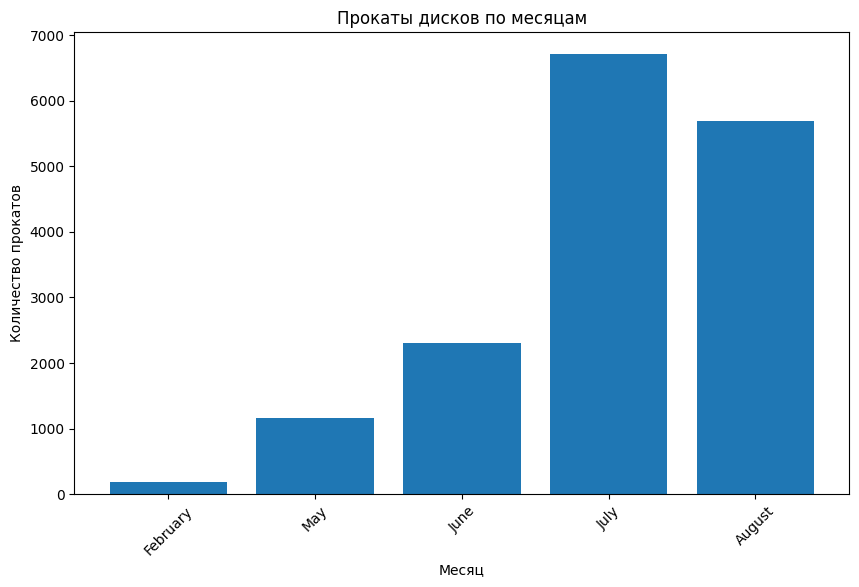

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(months, rentals)
ax.set_xlabel("Месяц")
ax.set_ylabel("Количество прокатов")
ax.set_title("Прокаты дисков по месяцам")
ax.tick_params(axis='x', rotation=45)
plt.show()